In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

emploi = pd.read_csv("DS_RP_EMPLOI_LR_COMP_2023_data.csv",sep=";")
emploi = emploi [['TIME_PERIOD' ,'EMPSTA_ENQ','GEO_OBJECT','GEO','OBS_VALUE','PCS']]

emploi_dep = emploi.loc[emploi["GEO_OBJECT"] == "DEP"]
emploi_dep = emploi_dep.loc[emploi_dep["PCS"] == "_T"]
emploi_dep = emploi_dep.loc[emploi_dep["TIME_PERIOD"] == 2023]

dep_aca = pd.read_csv("correspondance dep-aca.csv",sep=";")
dep_aca.head()

emploi_aca= emploi_dep.merge(
  dep_aca,
  left_on = ["GEO"],
  right_on = ["Departement"],
  how = "left"
)

emploi_aca= emploi_aca.groupby(["Academie","EMPSTA_ENQ"]).agg({"OBS_VALUE":"sum"}).reset_index()
emploi_aca.head(15)


/tmp/ipykernel_1977/410503149.py:5: DtypeWarning: Columns (0: GEO) have mixed types. Specify dtype option on import or set low_memory=False.
  emploi = pd.read_csv("DS_RP_EMPLOI_LR_COMP_2023_data.csv",sep=";")


,Academie,EMPSTA_ENQ,OBS_VALUE
0,AIX-MARSEILLE,1,1.177153e+06
1,AIX-MARSEILLE,1T2,1.305135e+06
2,AIX-MARSEILLE,2,1.279815e+05
3,AMIENS,1,7.694747e+05
4,AMIENS,1T2,8.656820e+05
5,AMIENS,2,9.620734e+04
6,BESANCON,1,4.898079e+05
7,BESANCON,1T2,5.373487e+05
8,BESANCON,2,4.754077e+04
9,BORDEAUX,1,1.500369e+06


In [3]:
ratio = (emploi_aca[emploi_aca["EMPSTA_ENQ"].isin(["1", "1T2"])]
    .pivot(index="Academie", columns="EMPSTA_ENQ", values="OBS_VALUE"))

#j'avoue cette dernière ligne c'est chat

ratio["ratio"] = ratio["1"] / ratio["1T2"]

emploi_aca["taux d'activité"] = emploi_aca["Academie"].map(ratio["ratio"])

emploi_aca = emploi_aca.loc[emploi_aca["EMPSTA_ENQ"] == "1"]

emploi_aca.sort_values(by="taux d'activité", ascending=False).head(100)



,Academie,EMPSTA_ENQ,OBS_VALUE,taux d'activité
57,NANTES,1,1.685097e+06,0.921427
18,CORSE,1,1.422976e+05,0.920397
27,GRENOBLE,1,1.527238e+06,0.918724
75,RENNES,1,1.429865e+06,0.917003
15,CLERMONT-FERRAND,1,5.549894e+05,0.916058
87,VERSAILLES,1,2.599955e+06,0.915211
12,CAEN,1,5.992905e+05,0.914382
66,PARIS,1,1.039014e+06,0.913363
45,LYON,1,1.457338e+06,0.912833
42,LIMOGES,1,2.835912e+05,0.911578


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

bac = pd.read_csv("fr-en-baccalaureat-par-academie.csv",sep=";")
bac = bac.loc[bac["Voie"] == "BAC GENERAL"]

bac["Sexe"]= bac["Sexe"].replace("MASCULIN", "GARCONS")
bac["Sexe"]= bac["Sexe"].replace("FEMININ", "FILLES")
bac.head(5)

bac_aca=bac.groupby("Libellé académie").agg({"Nombre d'inscrits": 'sum',"Nombre de présents":"sum","Nombre d'admis totaux": 'sum',"Nombre de refusés totaux":"sum"})


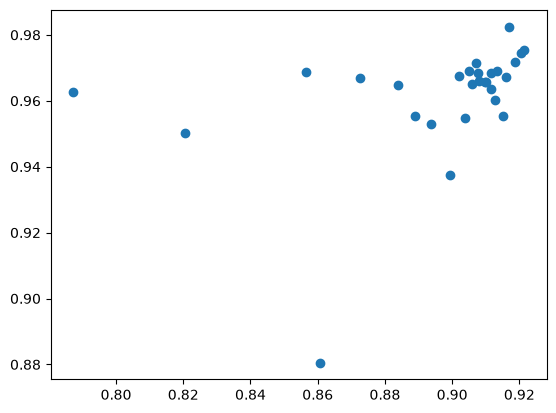

In [17]:
bac_emploi= bac_aca.merge(
  emploi_aca,
  left_on = ["Libellé académie"],
  right_on = ["Academie"],
  how = "left"
)
bac_emploi["taux de réussite"]=bac_emploi["Nombre d'admis totaux"]/bac_emploi["Nombre de présents"]

bac_emploi.head()

plt.scatter(bac_emploi["taux d'activité"],bac_emploi["taux de réussite"])
